# B3. Histogram dan Perbaikan Citra
Lembar hitung 3.1, diagnosis mutu citra, perbandingan operasi titik dan ekualisasi pada citra bayangan, eksperimen CLAHE, dan perbaikan per kondisi cahaya.

In [2]:
# ===== Identitas dan lingkungan (jalankan paling awal) =====
import os, sys
NAMA, NIM, KELAS = "Hisham", "2330511007", "7A"      # ganti KELAS sesuai kelas Anda
SEED = int(NIM[-4:])                                   # 4 digit terakhir NIM -> 1007

try:                                                   # di Colab: simpan kerja di Google Drive
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = f"/content/drive/MyDrive/simuteh-{NIM}"
except ImportError:                                    # di komputer sendiri
    cwd = os.getcwd()
    ROOT = os.path.dirname(cwd) if os.path.basename(cwd) == "notebook" else os.path.abspath(f"simuteh-{NIM}")

for sub in ["notebook", "src", "hasil", "laporan"]:
    os.makedirs(f"{ROOT}/{sub}", exist_ok=True)
os.chdir(f"{ROOT}/notebook")
print("Folder kerja:", os.getcwd(), "| SEED =", SEED)

Mounted at /content/drive
Folder kerja: /content/drive/MyDrive/simuteh-2330511007/notebook | SEED = 1007


In [3]:
# Pastikan B1 sudah dijalankan di akun/folder yang sama
for p in ["../src/utils_cv.py", "../data/sintetis/label.csv"]:
    assert os.path.exists(p), f"{p} tidak ditemukan. Jalankan B1 (Run all) di akun dan folder yang sama dulu."
print("Prasyarat dari B1 lengkap.")

# ===== Impor pustaka dan fungsi bantu =====
sys.path.append("../src")
import time, json
import cv2, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from utils_cv import baca, tampil, kontras_bercak, statistik
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)

label = pd.read_csv("../data/sintetis/label.csv")

def muat(nama):
    """Mengembalikan (citra, mask_daun, mask_bercak) untuk satu berkas."""
    img = baca(f"../data/sintetis/citra/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb

Prasyarat dari B1 lengkap.


## Langkah 3.1: verifikasi lembar hitung

In [4]:
M = np.array([[1, 2, 2, 3], [2, 2, 3, 3], [1, 2, 3, 4], [2, 3, 3, 2]])
L = 8
level = np.arange(L)
n = np.array([(M == v).sum() for v in level])
print("a) histogram:", {int(v): int(c) for v, c in zip(level, n) if c})

regang = np.floor((M - M.min()) / (M.max() - M.min()) * (L - 1) + 0.5).astype(int)
print("b) peregangan 0-7:\n", regang)

pdf = n / M.size; cdf = pdf.cumsum(); s = np.round((L - 1) * cdf).astype(int)
tabel_eq = pd.DataFrame({"r": level, "n": n, "PDF": pdf.round(4), "CDF": cdf.round(4),
                         "7 x CDF": ((L - 1) * cdf).round(2), "s": s})
print("c) tabel ekualisasi:"); display(tabel_eq)
print("   matriks hasil ekualisasi:\n", s[M])

print("d) negatif r=60 ->", 255 - 60)
for r in (120, 210):
    mentah = 1.4 * r - 30
    print(f"   kontras r={r}: {mentah:.1f} -> setelah clipping {int(np.clip(mentah, 0, 255))}")
for g in (0.6, 1.8):
    print(f"   gamma {g} pada r=100: {255 * (100 / 255) ** g:.1f}")

a) histogram: {1: 2, 2: 7, 3: 6, 4: 1}
b) peregangan 0-7:
 [[0 2 2 5]
 [2 2 5 5]
 [0 2 5 7]
 [2 5 5 2]]
c) tabel ekualisasi:


,r,n,PDF,CDF,7 x CDF,s
0,0,0,0.0000,0.0000,0.00,0
1,1,2,0.1250,0.1250,0.88,1
2,2,7,0.4375,0.5625,3.94,4
3,3,6,0.3750,0.9375,6.56,7
4,4,1,0.0625,1.0000,7.00,7
5,5,0,0.0000,1.0000,7.00,7
6,6,0,0.0000,1.0000,7.00,7
7,7,0,0.0000,1.0000,7.00,7


   matriks hasil ekualisasi:
 [[1 4 4 7]
 [4 4 7 7]
 [1 4 7 7]
 [4 7 7 4]]
d) negatif r=60 -> 195
   kontras r=120: 138.0 -> setelah clipping 138
   kontras r=210: 264.0 -> setelah clipping 255
   gamma 0.6 pada r=100: 145.4
   gamma 1.8 pada r=100: 47.3


## Kode 3.1: statistik dan histogram untuk diagnosis

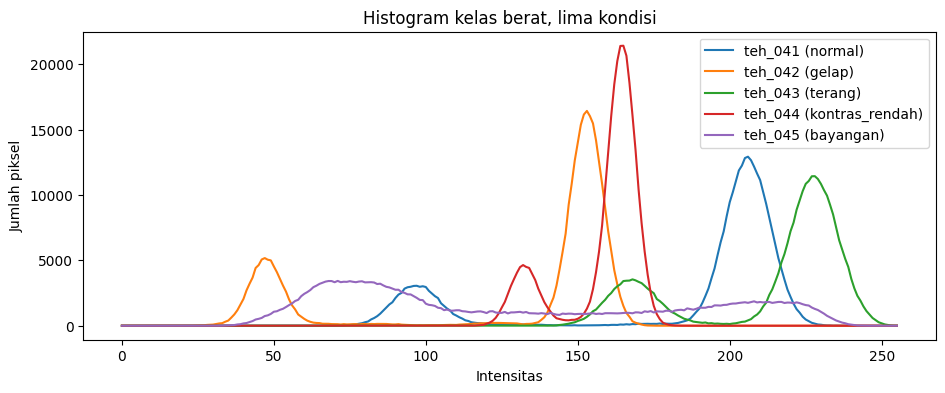

,citra,kondisi,rerata,simpangan_baku,min,maks,persen_gelap,persen_terang,diagnosis,usulan_perbaikan
0,teh_041,normal,183.4,44.2,64,237,0.0,41.0,cukup baik,tidak perlu perbaikan
1,teh_042,gelap,126.6,45.4,15,178,15.2,0.0,terlalu gelap,"gamma < 1 (mis. 0,6)"
2,teh_043,terang,213.0,26.7,132,255,0.0,74.9,terlalu terang,"gamma > 1 (mis. 1,6)"
3,teh_044,kontras_rendah,158.5,13.2,113,186,0.0,0.0,kontras rendah,peregangan kontras (persentil 2-98)
4,teh_045,bayangan,127.8,57.9,28,248,1.8,15.0,cahaya tidak merata (bayangan),"CLAHE lokal (clip 1, tile 4)"
5,teh_021,normal,168.7,42.3,64,228,0.0,4.2,cukup baik,tidak perlu perbaikan
6,teh_022,gelap,117.4,39.5,23,166,15.6,0.0,terlalu gelap,"gamma < 1 (mis. 0,6)"
7,teh_023,terang,215.0,28.4,142,251,0.0,73.4,terlalu terang,"gamma > 1 (mis. 1,6)"
8,teh_024,kontras_rendah,153.7,13.8,103,191,0.0,0.0,kontras rendah,peregangan kontras (persentil 2-98)
9,teh_025,bayangan,124.0,55.6,28,239,1.6,10.2,cahaya tidak merata (bayangan),"CLAHE lokal (clip 1, tile 4)"


In [5]:
kondisi_ = label.set_index("nama_file").kondisi_cahaya
daftar_uji = [f"teh_{i:03d}.png" for i in list(range(41, 46)) + list(range(21, 26))]

baris = []
plt.figure(figsize=(11, 4))
for nm in daftar_uji:
    im, _, _ = muat(nm)
    g = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)
    st = statistik(g)
    baris.append({"citra": nm[:7], "kondisi": kondisi_[nm], **st})
    if nm in daftar_uji[:5]:
        plt.plot(cv2.calcHist([g], [0], None, [256], [0, 256]), label=f"{nm[:7]} ({kondisi_[nm]})")
plt.xlabel("Intensitas"); plt.ylabel("Jumlah piksel"); plt.legend(); plt.title("Histogram kelas berat, lima kondisi")
plt.savefig("../hasil/b3_histogram_5kondisi.png", dpi=120); plt.show()

stat = pd.DataFrame(baris)

def diagnosis(r):
    if r.simpangan_baku < 20: return "kontras rendah", "peregangan kontras (persentil 2-98)"
    if r.rerata > 200:        return "terlalu terang", "gamma > 1 (mis. 1,6)"
    if r.maks < 200:          return "terlalu gelap", "gamma < 1 (mis. 0,6)"
    if r.simpangan_baku > 50: return "cahaya tidak merata (bayangan)", "CLAHE lokal (clip 1, tile 4)"
    return "cukup baik", "tidak perlu perbaikan"

stat[["diagnosis", "usulan_perbaikan"]] = stat.apply(lambda r: pd.Series(diagnosis(r)), axis=1)
display(stat); stat.to_csv("../hasil/b3_tabel_diagnosis.csv", index=False)

## Kode 3.2: operasi titik, peregangan, gamma, ekualisasi, dan CLAHE (teh_045, bayangan)

,metode,parameter,KB,simpangan_baku
0,asli,-,1.61,57.9
1,negatif,255 - r,1.61,57.9
2,cerah+50,+50,1.61,54.6
3,kontras,"1,5 r - 40",1.61,78.8
4,regang,persentil 2-98,1.66,82.1
5,gamma0.5,"gamma 0,5",1.43,40.9
6,gamma1.8,"gamma 1,8",1.94,64.1
7,ekualisasi,global,1.22,73.4
8,CLAHE,"clip 2, tile 8",2.09,48.8


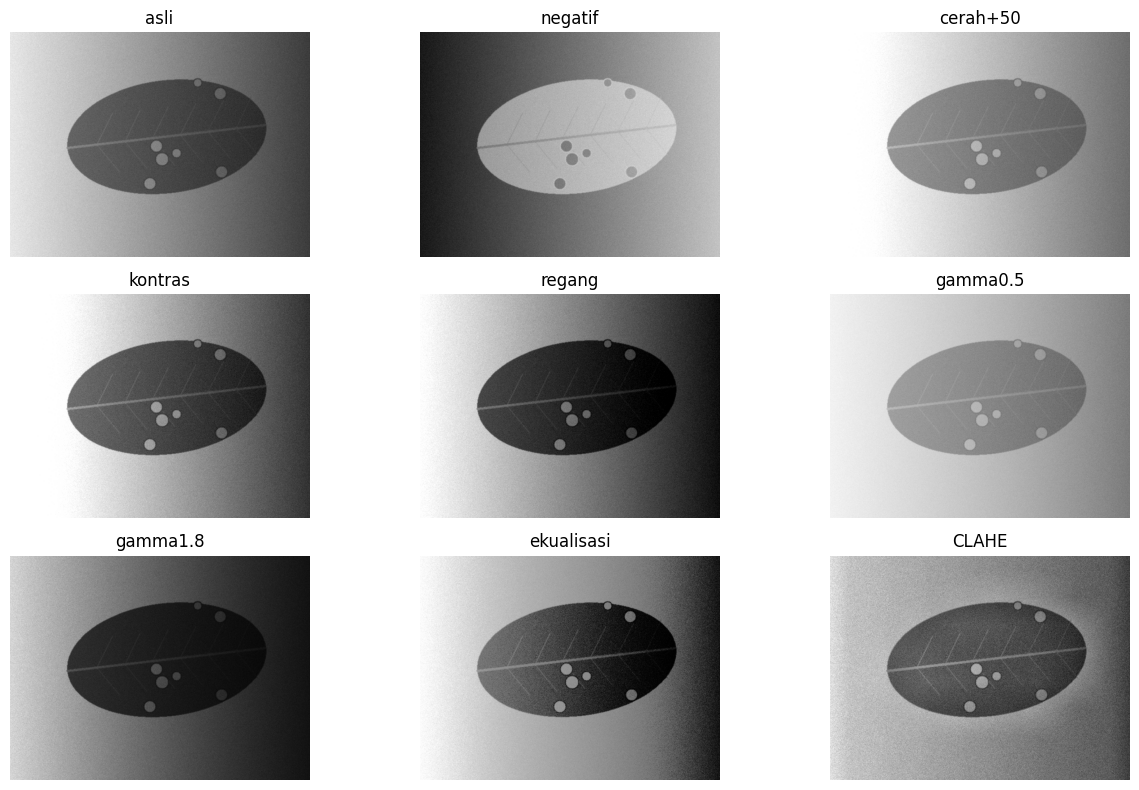

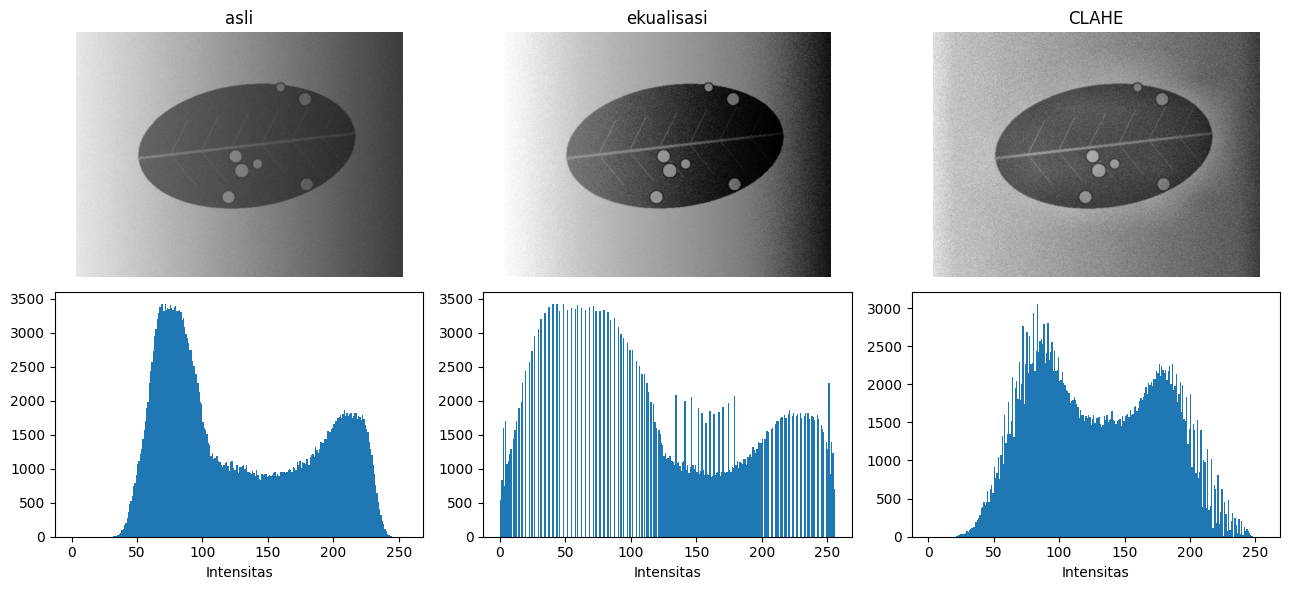

In [6]:
nama = "teh_045.png"
img, md, mb = muat(nama)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

def lut_gamma(g):
    return np.clip(255 * (np.arange(256) / 255) ** g, 0, 255).astype(np.uint8)

p2, p98 = np.percentile(gray, (2, 98))
metode = {
    "asli":       ("-",                gray),
    "negatif":    ("255 - r",          255 - gray),
    "cerah+50":   ("+50",              cv2.add(gray, 50)),
    "kontras":    ("1,5 r - 40",       cv2.convertScaleAbs(gray, alpha=1.5, beta=-40)),
    "regang":     ("persentil 2-98",   np.clip((gray - p2) / (p98 - p2) * 255, 0, 255).astype(np.uint8)),
    "gamma0.5":   ("gamma 0,5",        cv2.LUT(gray, lut_gamma(0.5))),
    "gamma1.8":   ("gamma 1,8",        cv2.LUT(gray, lut_gamma(1.8))),
    "ekualisasi": ("global",           cv2.equalizeHist(gray)),
    "CLAHE":      ("clip 2, tile 8",   cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(gray)),
}
tab32 = pd.DataFrame([[k, par, round(kontras_bercak(c, md, mb), 2), round(float(c.std()), 1)]
                      for k, (par, c) in metode.items()], columns=["metode", "parameter", "KB", "simpangan_baku"])
display(tab32); tab32.to_csv("../hasil/b3_tabel_perbaikan_bayangan.csv", index=False)

tampil([c for _, c in metode.values()], list(metode.keys()), baris=3, ukuran=(13, 8))
plt.savefig("../hasil/b3_panel_metode.png", dpi=110); plt.show()

# citra dan histogram berdampingan (tata letak seperti Gambar 4)
tiga = ["asli", "ekualisasi", "CLAHE"]
fig, ax = plt.subplots(2, 3, figsize=(13, 6))
for j, k in enumerate(tiga):
    c = metode[k][1]
    ax[0, j].imshow(c, cmap="gray", vmin=0, vmax=255); ax[0, j].set_title(k); ax[0, j].axis("off")
    ax[1, j].hist(c.ravel(), bins=256, range=(0, 256)); ax[1, j].set_xlabel("Intensitas")
plt.tight_layout(); plt.savefig("../hasil/b3_hist_asli_eq_clahe.png", dpi=110); plt.show()

## Kode 3.3: eksperimen CLAHE dan CLAHE pada citra warna

KB Gray menurut clipLimit (baris) dan tile (kolom)


tile,4,8,16
clipLimit,,,
1.0,2.45,2.18,2.29
2.0,2.45,2.09,2.08
4.0,2.17,1.81,1.85


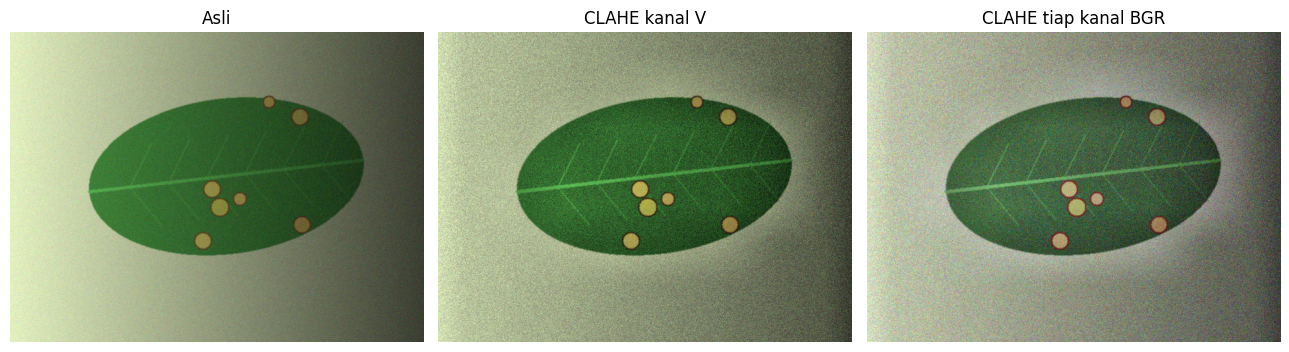

CLAHE kanal V        : rerata pergeseran Hue di area daun = 0.05
CLAHE tiap kanal BGR : rerata pergeseran Hue di area daun = 13.68


In [7]:
hasil_c = [[clip, tile, round(kontras_bercak(cv2.createCLAHE(clip, (tile, tile)).apply(gray), md, mb), 2)]
           for clip in (1.0, 2.0, 4.0) for tile in (4, 8, 16)]
tab33 = pd.DataFrame(hasil_c, columns=["clipLimit", "tile", "KB"]).pivot(index="clipLimit", columns="tile", values="KB")
print("KB Gray menurut clipLimit (baris) dan tile (kolom)"); display(tab33)

clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
hsv[:, :, 2] = clahe.apply(hsv[:, :, 2])
via_v = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)
via_bgr = cv2.merge([clahe.apply(c) for c in cv2.split(img)])
tampil([img, via_v, via_bgr], ["Asli", "CLAHE kanal V", "CLAHE tiap kanal BGR"], ukuran=(13, 3.8))
plt.savefig("../hasil/b3_clahe_warna.png", dpi=110); plt.show()

# bukti kuantitatif: seberapa jauh Hue (warna) bergeser pada area daun
H0 = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)[:, :, 0].astype(int)
for nm, im2 in [("kanal V", via_v), ("tiap kanal BGR", via_bgr)]:
    H1 = cv2.cvtColor(im2, cv2.COLOR_BGR2HSV)[:, :, 0].astype(int)
    geser = np.minimum(np.abs(H1 - H0), 180 - np.abs(H1 - H0))[md > 0].mean()
    print(f"CLAHE {nm:15s}: rerata pergeseran Hue di area daun = {geser:.2f}")

## Langkah 3.5: satu perbaikan per kondisi, pada kelas berat dan ringan

,kondisi,citra,kelas,perbaikan,rerata_sebelum,rerata_sesudah,KB_sebelum,KB_sesudah
0,gelap,teh_042,berat,"gamma 0,6",126.6,163.5,5.42,4.60
1,gelap,teh_022,ringan,"gamma 0,6",117.4,156.7,3.90,3.30
2,terang,teh_043,berat,"gamma 1,6",213.0,192.1,2.73,2.91
3,terang,teh_023,ringan,"gamma 1,6",215.0,195.3,1.99,2.10
4,kontras_rendah,teh_044,berat,regang 2-98,158.5,174.3,2.49,2.73
5,kontras_rendah,teh_024,ringan,regang 2-98,153.7,163.7,1.81,1.94
6,bayangan,teh_045,berat,CLAHE 1 / 4x4,127.8,127.8,1.61,2.45
7,bayangan,teh_025,ringan,CLAHE 1 / 4x4,124.0,125.0,0.39,1.05


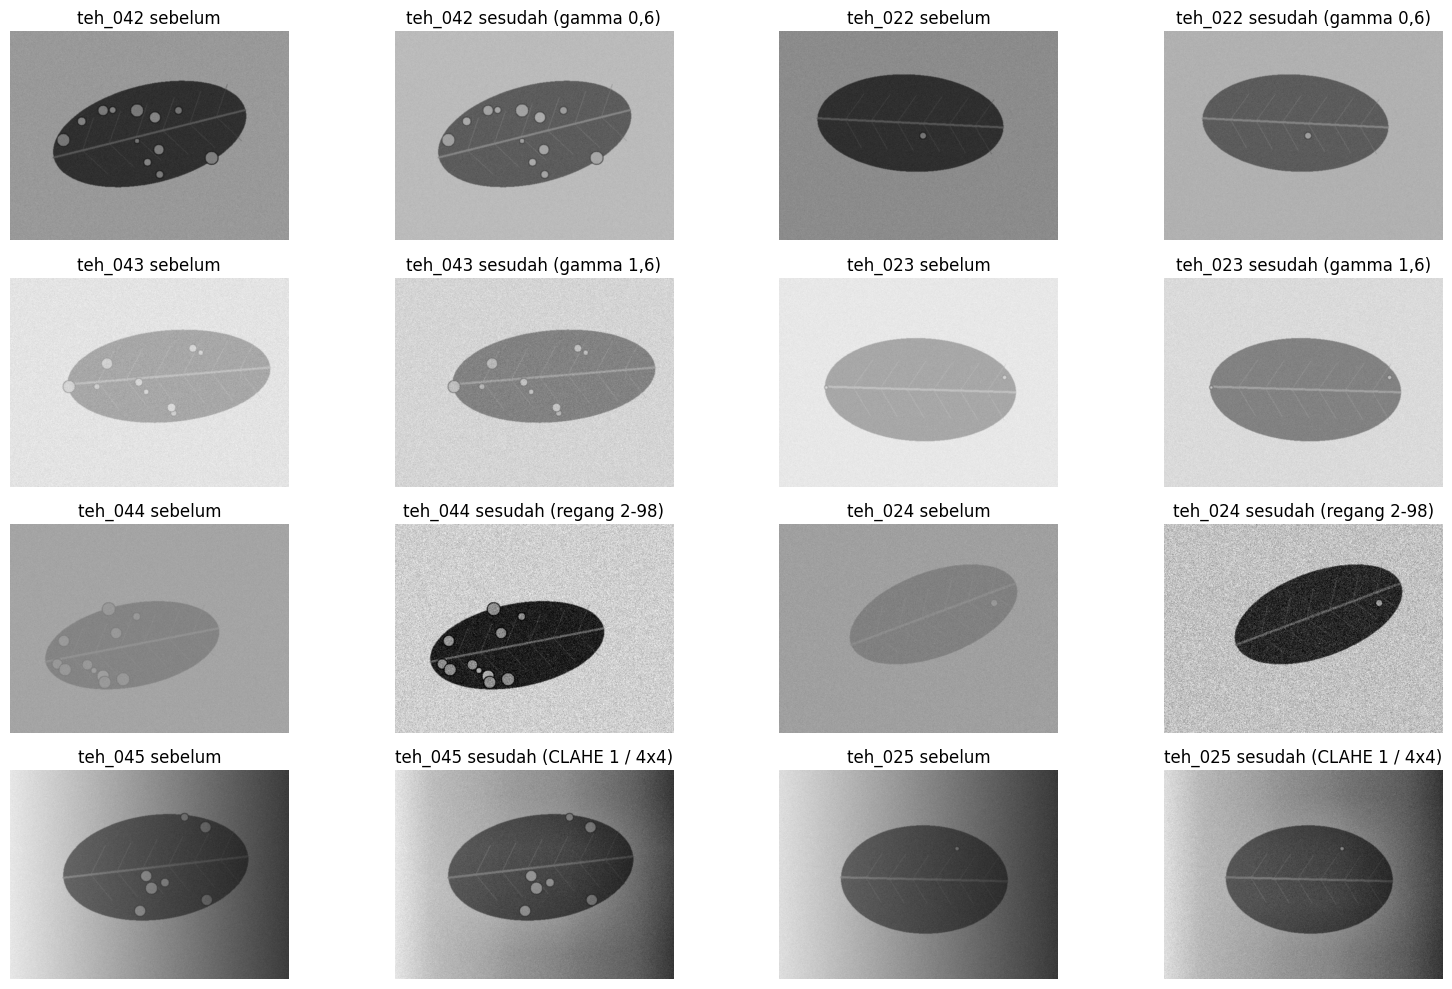

In [8]:
def regang_pers(x):
    lo, hi = np.percentile(x, (2, 98))
    return np.clip((x - lo) / (hi - lo) * 255, 0, 255).astype(np.uint8)

perbaikan = {
    "gelap":          ("gamma 0,6",      lambda x: cv2.LUT(x, lut_gamma(0.6)),                 ("teh_042.png", "teh_022.png")),
    "terang":         ("gamma 1,6",      lambda x: cv2.LUT(x, lut_gamma(1.6)),                 ("teh_043.png", "teh_023.png")),
    "kontras_rendah": ("regang 2-98",    regang_pers,                                          ("teh_044.png", "teh_024.png")),
    "bayangan":       ("CLAHE 1 / 4x4",  lambda x: cv2.createCLAHE(1.0, (4, 4)).apply(x),      ("teh_045.png", "teh_025.png")),
}
baris, daftar, judul = [], [], []
for kond, (nama_m, f, pasangan) in perbaikan.items():
    for nm in pasangan:
        im, m_d, m_b = muat(nm)
        g_ = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY); out = f(g_)
        baris.append([kond, nm[:7], "berat" if nm in ("teh_042.png", "teh_043.png", "teh_044.png", "teh_045.png") else "ringan",
                      nama_m, round(float(g_.mean()), 1), round(float(out.mean()), 1),
                      round(kontras_bercak(g_, m_d, m_b), 2), round(kontras_bercak(out, m_d, m_b), 2)])
        daftar += [g_, out]; judul += [f"{nm[:7]} sebelum", f"{nm[:7]} sesudah ({nama_m})"]
tab35 = pd.DataFrame(baris, columns=["kondisi", "citra", "kelas", "perbaikan", "rerata_sebelum", "rerata_sesudah", "KB_sebelum", "KB_sesudah"])
display(tab35); tab35.to_csv("../hasil/b3_perbaikan_per_kondisi.csv", index=False)
tampil(daftar, judul, baris=4, ukuran=(16, 10))
plt.savefig("../hasil/b3_panel_per_kondisi.png", dpi=100); plt.show()